# NUMPY
---
## What's Numpy?
Numpy is a multi-dimensional array library . It can be used to store data in any shape, 1D array, 2D array, 3D array.

![image.png](arrays.png)



## Numpy vs Lists?
Numpy is used instead of lists because of its computation speed. Numpy uses fixed values. For instance, in the array below, computers don't recognize five as a nummber. They only recognize the binary that represents 5, (`0000101`), of 8-bits (1-byte). 

![image.png](3x4_array.png) 


Computers read information in bytes. So, with numpy, the 1-byte by default, will be that casted into type `int32` which represents 5 in a total memory space of 4 bytes (`00000000 00000000 00000000 00000101`)  or you could specify within numpy the type, say type `int16` which takes 2 bytes of memory space (`00000000 00000101`) or even `int8` which is a single byte. 

On the hand, with lists, a lot more information is stored as an integer. The int type consists of the following which when broken down into the actual binary they represent:

- Size (4 bytes), Reference Count (8 bytes), Object Type (8 bytes), Object value (8 bytes).

These take up much more memory space. 



## Why Numpy is Faster.
- It reads less bytes of memory
- There's no type checking when iteration through objects.

- **Contiguous memory**: Numpy stores array elements in contiguous block of memory, meaning neighboouring elements are physically close together.
Think of it like parking cars:

  - **Python lists** = Bumpy / Scattered Parking Lot

    ```python
    my_list = [1, "hello", 3.14, [1,2]]

    ```
    In Ram, each memory in a lit is just a pointer. The actual objects 1, "hello", 3.14 can live anywhere in memory.

    ```text
    List object: [ptr1] [ptr2] [ptr3] [ptr4]
                 ↓      ↓     ↓      ↓
               int   string  float  list  ←-- scattered all over RAM
    ```
    **Pros**:
    - Flexible: Can hold int, str, list all together
    - Dynamic: Easy to `.append()`, `.insert()`, `.pop()`. Because you're just adding/removing pointers.

    **Cons**:
    - Not contiguous: CPU has to "_jump around_" RAM to find each item. Cache misses = slow
    - Big overhead: Each item has ~28-bytes of Python object overhead + 8 bytes for the pointer.

  - **Numpy Array** = Perfect Contiguous Parking Lot
    ```python
    import numpy as np
    my_arr = np.array([10,20,30,40], dtype=np.int32)   # all int32 values are packed back-to-back in one single block of memory.
    ```
    ```text
    RAM: [4 bytes][4 bytes][4 bytes][4 bytes]
            10       20       30       40
    ```
    When PC accesses 10, it can quickly load 20, 30, etc. because they're nearby in memory. That's one reason Numpy arrays can be very fast.
    
    **Pros**:
    - Contiguous: CPU loads 1 chunck and gets 10 items at once. Super cache friendly = 10x-100x faster for math
    - Small: 4 bytes per int32. No object overhead.
    - vectorized: Can do `arr * 2` in 1 C-loop instead of a Python loop

    **Cons**:
    - Rigid: All items must be sme type dtype. Can't mix int and string.
    - Fixed Size: Resizing means "_copy whole array to new parking lot_". `.append()` is expensive

  Contiguous blocks improves CPU cache usage: when CPU loads one element, it often loads nearby elements into the cache too, so accessing the next elements is muct faster. Numpy alos performs operations in optimizzed compiled C code instead of Python loops, reduing Python-level overhead (i.e. extra work work or resources required to perform an operation).    


## Applications
- Mathematics (MATLAB Replacement)
- Plotting (Matplotlib)
- Backend (Pandas, Connect 4, Digital Photography)
- Machine Learning

### Basics

In [2]:
# Load numpy
import numpy as np


# initializing an array
# 1D array — Column vector
a = np.array([1,2,3])
# 2D array - Nested arrays
b = np.array([[9.0,8.0,7.0], [6.0,5.0,4.0]])  # 2 x 3 array
c = np.array([1,2,3], dtype="int32")  # specifiying dtype
a

array([1, 2, 3])

In [3]:
print(a)
print(b)
print(c)

[1 2 3]
[[9. 8. 7.]
 [6. 5. 4.]]
[1 2 3]


In [4]:
# Get Dimension
a.ndim, b.ndim, c.ndim

(1, 2, 1)

In [5]:
# Get Shape
a.shape, b.shape, c.shape

((3,), (2, 3), (3,))

In [6]:
# Get Type
a.dtype, b.dtype, c.dtype

(dtype('int64'), dtype('float64'), dtype('int32'))

In [7]:
# Get Size (in bytes)
# int8 / float 8 = 1 byte, 
a.itemsize, b.itemsize, c.itemsize
# a and b are int64 and float64 and so will take up more space

(8, 8, 4)

In [8]:
# If we set it to a smaller dtype, we will see a change in the memory size
# 
a = np.array([1,2,3], dtype='int8')
# 2D array - Nested arrays
b = np.array([[9.0,8.0,7.0], [6.0,5.0,4.0]], dtype='float16')

a.dtype, b.dtype

(dtype('int8'), dtype('float16'))

In [9]:
a.itemsize, b.itemsize    # 1 byte and 2 bytes respectively

(1, 2)

In [10]:
# Get Total Size
# Total size (nbytes) is given by : 
# n_elements * byte_size: 3 x 8 = 24

a = np.array([1,2,3])                           # dtype=int64 by default

a.size * a.itemsize, a.nbytes   

(24, 24)

### Accessing/Changing specific elements, rows, columns, etc.

In [110]:
a = np.array([[1,2,3,4,5,6,7], [8,9,10,11,12,13,14]])

print(a)


[[ 1  2  3  4  5  6  7]
 [ 8  9 10 11 12 13 14]]


In [111]:
np.c_[a[0], a[1]]

array([[ 1,  8],
       [ 2,  9],
       [ 3, 10],
       [ 4, 11],
       [ 5, 12],
       [ 6, 13],
       [ 7, 14]])

In [12]:
# Get a specific element [r, c]
a[1, 5]


np.int64(13)

In [116]:
# Get a specific row [r, :]
a[0, :]

array([1, 2, 3, 4, 5, 6, 7])

In [14]:
# Get a specific column [:, c]
a[:, 4]

array([ 5, 12])

In [15]:
# More specifications [start_index:end_index:step_size] 
# from row 0 select the items from index 1 to 6(exclusive) in 2 steps
a[0, 1:6:2]    # returns [2, 4, 6]

array([2, 4, 6])

In [16]:
a[0, 1:-2:2]  

array([2, 4])

In [17]:
a[1, 1:-2:2]

array([ 9, 11])

In [18]:
# Replacing an element
print(a)
print()

print(a)
a[1,5] = 20 # Replacing the 6th element in the 2nd row with 20 (13 → 20)
print()

# Entire Column
a[:,2] = 5 # replacing column 3 with 5s
print(a)
print()

a[:,2] = [1,2]  # replacing with column 3 with 1 and 2
print(a)


[[ 1  2  3  4  5  6  7]
 [ 8  9 10 11 12 13 14]]

[[ 1  2  3  4  5  6  7]
 [ 8  9 10 11 12 13 14]]

[[ 1  2  5  4  5  6  7]
 [ 8  9  5 11 12 20 14]]

[[ 1  2  1  4  5  6  7]
 [ 8  9  2 11 12 20 14]]


In [19]:
# 3D example
b = np.array(
    [
        [[1,2], 
         [3,4]],  # 1st matrix (2x2)

        [[5,6], 
         [7,8]]   # 2nd matrix (2x2)
    ]             # All together 2x(2x2) = 2x2x2
)                         
print(b)

[[[1 2]
  [3 4]]

 [[5 6]
  [7 8]]]


In [20]:
b.ndim, b.shape

(3, (2, 2, 2))

In [21]:
# Get specific element (work outside in)
# Let's get 4  
b[0, 1, 1]

np.int64(4)

In [22]:
# An more specific selection
b[1,1,1], b[1][1][1]    # Both produce the same result

(np.int64(8), np.int64(8))

In [23]:
b[1, 1]

array([7, 8])

In [24]:
# Replace
b[:, 1,:] = [[0, 0], [1,1]]
b


array([[[1, 2],
        [0, 0]],

       [[5, 6],
        [1, 1]]])

### Initializing Different Types of Arrays


In [25]:
# All zeros matrix
np.zeros((2,3))

array([[0., 0., 0.],
       [0., 0., 0.]])

In [26]:
# All 1s matrix
np.ones((4, 2, 2), dtype='int16')

array([[[1, 1],
        [1, 1]],

       [[1, 1],
        [1, 1]],

       [[1, 1],
        [1, 1]],

       [[1, 1],
        [1, 1]]], dtype=int16)

In [27]:
# All other number
np.full((2,2), 99, dtype='int32')


array([[99, 99],
       [99, 99]], dtype=int32)

In [28]:
# Any othr number (full_like)
# Allows us to use  shape that is already built
f = np.full(a.shape, 4)        # Takes the shape and fill_value
g = np.full_like(a, 4)         # Takes an array and fill_value
print(f, "\n")
print(g)

[[4 4 4 4 4 4 4]
 [4 4 4 4 4 4 4]] 

[[4 4 4 4 4 4 4]
 [4 4 4 4 4 4 4]]


In [29]:
# Matrix of random numbers 
arr_1 = np.random.rand(4,2)
arr_2 = np.random.random_sample(a.shape)

print(arr_1,"\n\n", arr_2)

[[0.0771503  0.89053622]
 [0.7176128  0.30343973]
 [0.95518548 0.09702885]
 [0.36523412 0.43882751]] 

 [[0.53350345 0.83180243 0.65031167 0.92789233 0.07742799 0.1114932
  0.39629772]
 [0.45352062 0.14643081 0.77949415 0.26223642 0.72455305 0.20939663
  0.13204235]]


In [30]:
# Random integer values: [startindex, stopindex, size, dtype,...]
np.random.randint(-2, 8, size=(3,3), dtype='int16')

array([[-1,  0, -1],
       [ 4,  5, -1],
       [ 1,  2,  4]], dtype=int16)

In [31]:
# The Identity matrix (1s in the diagonal)
np.identity(5)     # 5 specifies the soze of the Identity matrix

array([[1., 0., 0., 0., 0.],
       [0., 1., 0., 0., 0.],
       [0., 0., 1., 0., 0.],
       [0., 0., 0., 1., 0.],
       [0., 0., 0., 0., 1.]])

In [32]:
np.trace(np.identity(5))

np.float64(5.0)

Arrays are conceptually vectors with one dimension. The are similar in Series in pandas. While matrices on the other hand, are conceptually similar to dataframes with 2 dimensions:

In [99]:
# Repeat an array
arr = np.array([[1,2,3]])
r1 = np.repeat(arr, 3, axis=0)   # repeats the same row

r1

array([[1, 2, 3],
       [1, 2, 3],
       [1, 2, 3]])

In [34]:
arr1 = np.array([[1,2,3]]) 
arr2 = np.array([[1],[2],[3]])
arr3 = np.array([1,2,3])[:, np.newaxis]

# arr2 & arr3 are equivalent

print(arr1, "\n")
print(arr2, "\n")
print(arr3)

[[1 2 3]] 

[[1]
 [2]
 [3]] 

[[1]
 [2]
 [3]]


In [35]:
arr = np.array([[1,2,3]])
arr.T

array([[1],
       [2],
       [3]])

In [36]:
matrix = np.ones((5,5)) 
print(matrix)

z = np.zeros((3,3))
print(z)

z[1,1] = 9
matrix[1:4, 1:4] = z   # or[1:-1, 1:-1]
 
print()

print(matrix)

[[1. 1. 1. 1. 1.]
 [1. 1. 1. 1. 1.]
 [1. 1. 1. 1. 1.]
 [1. 1. 1. 1. 1.]
 [1. 1. 1. 1. 1.]]
[[0. 0. 0.]
 [0. 0. 0.]
 [0. 0. 0.]]

[[1. 1. 1. 1. 1.]
 [1. 0. 0. 0. 1.]
 [1. 0. 9. 0. 1.]
 [1. 0. 0. 0. 1.]
 [1. 1. 1. 1. 1.]]


#### _Take extra precaution when copying arrays!!!_

In [37]:
a = np.array([1,2,3])
b = a      
b[0] = 100

print(a, b)    

[100   2   3] [100   2   3]


`b` points to the same thing as `a` so when we change the value of `b`, the value of `a` gets changed as well. It didn't make a copy. We can fix this by performing a shallow copy with `.copy()`

In [38]:
a = np.array([1,2,3])
b = a.copy()     
b[0] = 100

a, b


(array([1, 2, 3]), array([100,   2,   3]))

### Mathematics

Element-wise computation

In [39]:
a = np.array([1,2,3,4])
print(a)

[1 2 3 4]


In [40]:
print(a + 2)

[3 4 5 6]


In [41]:
print(a - 4)

[-3 -2 -1  0]


In [42]:
a / 2

array([0.5, 1. , 1.5, 2. ])

In [43]:
b = np.array([5,6,7,8])
a + b

array([ 6,  8, 10, 12])

In [44]:
a ** 2

array([ 1,  4,  9, 16])

In [45]:
# Take the sin, cos, tan of all values of matrix a

np.sin(a) , np.cos(a), np.tan(a)

(array([ 0.84147098,  0.90929743,  0.14112001, -0.7568025 ]),
 array([ 0.54030231, -0.41614684, -0.9899925 , -0.65364362]),
 array([ 1.55740772, -2.18503986, -0.14254654,  1.15782128]))

### Linear Algebra

In [46]:
a = np.ones((2,3))

b  = np.full((3,2), 2)
print(b)

# matrix multiplication
np.matmul(a,b)    

[[2 2]
 [2 2]
 [2 2]]


array([[6., 6.],
       [6., 6.]])

In [47]:
# determinant

c = np.identity(3)

print(np.linalg.det(c))

1.0


### Statistics

In [48]:
stats = np.array([[1,2,3], [4,5,6]])
stats

array([[1, 2, 3],
       [4, 5, 6]])

In [49]:
print(np.min(stats))           # min_value in the whole matrix
print(np.min(stats, axis=1))   # min_value along the column axis
print(np.min(stats, axis=0))   # min_value along the row axis
print(np.max(stats))           # max_values

1
[1 4]
[1 2 3]
6


In [50]:
print(np.sum(stats))           # summing all matrix elements 
print(np.sum(stats, axis=0))   # summing elements row-wise
print(np.sum(stats, axis=1))   # summing elements column-wise


21
[5 7 9]
[ 6 15]


### Reorganizing Arrays

In [51]:
initial = np.array([[1,2,3,4], [5,6,7,8]])

print(initial, initial.shape)

after = initial.reshape(8,1)     # also try (8,1), (4,2), (2,2,2)
print(after, after.shape)

[[1 2 3 4]
 [5 6 7 8]] (2, 4)
[[1]
 [2]
 [3]
 [4]
 [5]
 [6]
 [7]
 [8]] (8, 1)


In [52]:
# Vertical stacking vectors
v1 = np.array([1,2,3,4])
v2 = np.array([5,6,7,8])

print(np.vstack([v1,v2,v2,v2]))

[[1 2 3 4]
 [5 6 7 8]
 [5 6 7 8]
 [5 6 7 8]]


In [53]:
# Horizontal stack
h1 = np.ones((2,4))
h2 = np.zeros((2,2))

np.hstack((h1,h2))

array([[1., 1., 1., 1., 0., 0.],
       [1., 1., 1., 1., 0., 0.]])

### Miscellaneous

In [54]:
import random

numbers = random.choices((range(1, 100)))
print(numbers)

[31]


In [55]:
file_data = np.genfromtxt('data.txt', delimiter=',') # automatically casted into float type
file_data

array([[  1.,  13.,  21.,  11., 196.,  75.,   4.,   3.,  34.,   6.,   7.,
          8.,   0.,   1.,   2.,   3.,   4.,   5.],
       [  3.,  42.,  12.,  33., 766.,  75.,   4.,  55.,   6.,   4.,   3.,
          4.,   5.,   6.,   7.,   0.,  11.,  12.],
       [  1.,  22.,  33.,  11., 999.,  11.,   2.,   1.,  78.,   0.,   1.,
          2.,   9.,   8.,   7.,   1.,  76.,  88.]])

In [56]:
# changine data type
file_data = file_data.astype("int32")
file_data

array([[  1,  13,  21,  11, 196,  75,   4,   3,  34,   6,   7,   8,   0,
          1,   2,   3,   4,   5],
       [  3,  42,  12,  33, 766,  75,   4,  55,   6,   4,   3,   4,   5,
          6,   7,   0,  11,  12],
       [  1,  22,  33,  11, 999,  11,   2,   1,  78,   0,   1,   2,   9,
          8,   7,   1,  76,  88]], dtype=int32)

#### Boolean Masking and Advanced Indexing

In [57]:
file_data > 50     # return bool value "True" where at index positions that meet this condition


array([[False, False, False, False,  True,  True, False, False, False,
        False, False, False, False, False, False, False, False, False],
       [False, False, False, False,  True,  True, False,  True, False,
        False, False, False, False, False, False, False, False, False],
       [False, False, False, False,  True, False, False, False,  True,
        False, False, False, False, False, False, False,  True,  True]])

In [58]:
file_data[file_data > 50]    # returns the array of values that meet this condition

array([196,  75, 766,  75,  55, 999,  78,  76,  88], dtype=int32)

In [59]:
## Indexing with list 
# We can index using a list of index positions of the values of an array
a = np.array([1,2,3,4,5,6,7,8,9])

a[[1,2,8]]    

array([2, 3, 9])

In [60]:
print(file_data)

[[  1  13  21  11 196  75   4   3  34   6   7   8   0   1   2   3   4   5]
 [  3  42  12  33 766  75   4  55   6   4   3   4   5   6   7   0  11  12]
 [  1  22  33  11 999  11   2   1  78   0   1   2   9   8   7   1  76  88]]


In [61]:
print(np.any(file_data > 50, axis=0), "\n")    # True if any value > 50 in each column (reduce rows)
print(np.any(file_data > 50, axis=1), "\n")    # True if any value > 50 in each row (reduce columns)
print(np.all(file_data > 50, axis=0), "\n")    # True if all values > 50 in each column (reduce rows)
print(np.all(file_data > 50, axis=1), "\n")    # True if all values > 50 in each row (reduce columns)

[False False False False  True  True False  True  True False False False
 False False False False  True  True] 

[ True  True  True] 

[False False False False  True False False False False False False False
 False False False False False False] 

[False False False] 



`axis` tells Numpy which dimension to **collapse/reduce**, not which direction to look
by collapse/reduce we mean, take several values along an axis and combine them into a fewer values—usually one value. 

So:
- `axis=0` → collapse the rows → result for each column
- `axis=1` → collapse the columns → result for each row

Numpy is essentially saying:
> "_For every axis, through all the opposite axis and tell me whether ANY/ALL value is > 50_"


In [62]:
((file_data > 50) & (file_data < 100))    # Return all values > 50 AND < 100

array([[False, False, False, False, False,  True, False, False, False,
        False, False, False, False, False, False, False, False, False],
       [False, False, False, False, False,  True, False,  True, False,
        False, False, False, False, False, False, False, False, False],
       [False, False, False, False, False, False, False, False,  True,
        False, False, False, False, False, False, False,  True,  True]])

In [63]:
# and in reverse
(~((file_data > 50) & (file_data < 100)))     # ~ means NOT

array([[ True,  True,  True,  True,  True, False,  True,  True,  True,
         True,  True,  True,  True,  True,  True,  True,  True,  True],
       [ True,  True,  True,  True,  True, False,  True, False,  True,
         True,  True,  True,  True,  True,  True,  True,  True,  True],
       [ True,  True,  True,  True,  True,  True,  True,  True, False,
         True,  True,  True,  True,  True,  True,  True, False, False]])

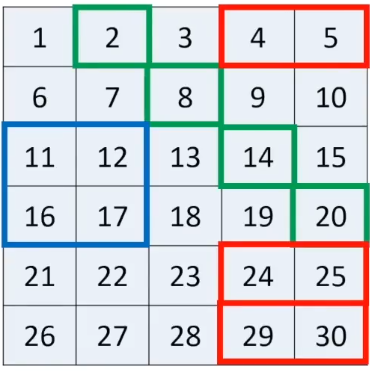

In [64]:
# Lets try to produce the highlighted portions in the matrix given above

matrix = np.arange(1, 31).reshape(6,5)

print(matrix)

[[ 1  2  3  4  5]
 [ 6  7  8  9 10]
 [11 12 13 14 15]
 [16 17 18 19 20]
 [21 22 23 24 25]
 [26 27 28 29 30]]


In [65]:
green = matrix[[0,1,2,3], [1,2,3,4]]
blue = matrix[2:4, 0:2]
red = matrix[[0,4,5], 3:]

print(green, "\n")
print(blue, "\n")
print(red)

[ 2  8 14 20] 

[[11 12]
 [16 17]] 

[[ 4  5]
 [24 25]
 [29 30]]


### More concepts with Neural-Nine
---

In [66]:
# Multidimenstional numpy arrays
a_mul = np.array([[1,2.0,3],
                  [4, "hello", 6],  # string changes the array to numpy string
                  [7,8,9]])
b_mul = np.array([[1,2,3],
                  [4, 1.0, 6],  # float value changes the array to numpy float
                  [7,8,9]])


print(type(a_mul[0][0]))
print(type(b_mul[0][0]))
print(a_mul[0][0])
print(b_mul[0][0])
print(a_mul[0][0].dtype)

# a_mul[0][0]

<class 'numpy.str_'>
<class 'numpy.float64'>
1
1.0
<U1


Mixing data types changes the datatype of the entire array into  a particular type.

And we cannot type-cast a low ("hello") into an integer. However, we can type-cast numbers written as strings:

In [67]:
a = np.array([[1,2,3], [5,"6",7]], dtype="int32")
print(a[1][1])
print(type(a[0][0]))

6
<class 'numpy.int32'>


In [68]:
d = {'1': 'A'}

a = np.array([[1,2,3], [5,d,7]], dtype="<U7")
print(a.dtype)    
print(type(a[0][0]))

<U7
<class 'numpy.str_'>


Whenever we have a non-primitive datatype we can type-cast into everything becomes an object.

We can also specify the datatype as string:

In [69]:
a = np.array([[1,2,3],

              [5,d,7]])

print(a.dtype)    



print(type(a[0][0]))

object
<class 'int'>


In [70]:
# Unlike zeros, ones and other functions takes allocates 
# a space without initializing the values
a = np.empty((5,5,5))  
print(a)

[[[0.00000000e+000 6.95236068e-310 4.77267414e-321             nan
   2.77201037e-302]
  [2.46275466e-287 1.71440779e-321 1.69183032e-292 0.00000000e+000
   1.00051796e-316]
  [2.65832297e-316 7.36377546e-312 5.64889340e-283 1.74220274e-311
   4.67824359e-307]
  [5.46436604e-321 0.00000000e+000 4.67911276e-307 7.99398215e-321
   0.00000000e+000]
  [4.51985103e-311 0.00000000e+000 0.00000000e+000 8.90178339e-311
   1.30976803e-320]]

 [[1.02123638e-315 0.00000000e+000 8.74934642e-302 1.94217205e-320
   2.23904750e-273]
  [8.34156649e-311 1.43859146e-268 1.35279864e-315 0.00000000e+000
   3.06227125e-302]
  [1.06148781e-234 0.00000000e+000 3.91887205e-293 1.27282204e-315
   4.68162860e-307]
  [2.31716788e-320 0.00000000e+000 2.19571750e-273 8.34156649e-311
   4.04927497e-254]
  [8.55552848e-211 0.00000000e+000 0.00000000e+000 1.85014098e-315
   0.00000000e+000]]

 [[7.65567812e-303 3.06227125e-302 1.06148781e-234 0.00000000e+000
   4.67277060e-307]
  [2.57012949e-320 0.00000000e+000 1.32

In [71]:
# Generating sequences
# arange(start, stop, step)
x_values = np.arange(0, 1005, 5)
print(x_values)

[   0    5   10   15   20   25   30   35   40   45   50   55   60   65
   70   75   80   85   90   95  100  105  110  115  120  125  130  135
  140  145  150  155  160  165  170  175  180  185  190  195  200  205
  210  215  220  225  230  235  240  245  250  255  260  265  270  275
  280  285  290  295  300  305  310  315  320  325  330  335  340  345
  350  355  360  365  370  375  380  385  390  395  400  405  410  415
  420  425  430  435  440  445  450  455  460  465  470  475  480  485
  490  495  500  505  510  515  520  525  530  535  540  545  550  555
  560  565  570  575  580  585  590  595  600  605  610  615  620  625
  630  635  640  645  650  655  660  665  670  675  680  685  690  695
  700  705  710  715  720  725  730  735  740  745  750  755  760  765
  770  775  780  785  790  795  800  805  810  815  820  825  830  835
  840  845  850  855  860  865  870  875  880  885  890  895  900  905
  910  915  920  925  930  935  940  945  950  955  960  965  970  975
  980 

In [72]:
# A similar function is linspace(start, stop, num)
# returns evenly spaced over a specified interval
# instead of step size we specifiy the number of values we want to generate
x_values  = np.linspace(0, 1000, 1000)
print(x_values)

[   0.            1.001001      2.002002      3.003003      4.004004
    5.00500501    6.00600601    7.00700701    8.00800801    9.00900901
   10.01001001   11.01101101   12.01201201   13.01301301   14.01401401
   15.01501502   16.01601602   17.01701702   18.01801802   19.01901902
   20.02002002   21.02102102   22.02202202   23.02302302   24.02402402
   25.02502503   26.02602603   27.02702703   28.02802803   29.02902903
   30.03003003   31.03103103   32.03203203   33.03303303   34.03403403
   35.03503504   36.03603604   37.03703704   38.03803804   39.03903904
   40.04004004   41.04104104   42.04204204   43.04304304   44.04404404
   45.04504505   46.04604605   47.04704705   48.04804805   49.04904905
   50.05005005   51.05105105   52.05205205   53.05305305   54.05405405
   55.05505506   56.05605606   57.05705706   58.05805806   59.05905906
   60.06006006   61.06106106   62.06206206   63.06306306   64.06406406
   65.06506507   66.06606607   67.06706707   68.06806807   69.06906907
   70.07

In [73]:
# nan and inf
print(np.nan)     # used moslty for filining missing values
print(np.inf)     # return infinity values instead of throwing an exception

# Inspect the nan and inf values
print(np.isinf(np.inf))
print(np.isinf(np.inf))
print(np.isnan(np.sqrt(-1)))
print(np.isinf(np.array([10]) / 0))

nan
inf
True
True
True
[ True]


C:\Users\Favor\AppData\Local\Temp\ipykernel_148100\1903189567.py:8: RuntimeWarning: invalid value encountered in sqrt
  print(np.isnan(np.sqrt(-1)))
C:\Users\Favor\AppData\Local\Temp\ipykernel_148100\1903189567.py:9: RuntimeWarning: divide by zero encountered in divide
  print(np.isinf(np.array([10]) / 0))


In [74]:
print(np.array(-1))
print(np.array([10]) / 0)

-1
[inf]


C:\Users\Favor\AppData\Local\Temp\ipykernel_148100\2769768650.py:2: RuntimeWarning: divide by zero encountered in divide
  print(np.array([10]) / 0)


### Mathematical Operations

In [75]:
# Lists
l1 = [1,2,3,4,5]
l2 = [6,7,8,9,10]

# Numpy array
a1 = np.array(l1)
a2 = np.array(l2)

# Multiplication
print(l1 * 5)   # basically repeats the list 5 times
print(a1 * 5)   # mutlilpies each element by 5 (scalar multiplication)

[1, 2, 3, 4, 5, 1, 2, 3, 4, 5, 1, 2, 3, 4, 5, 1, 2, 3, 4, 5, 1, 2, 3, 4, 5]
[ 5 10 15 20 25]


In [76]:
# Addition
# print(l1 + 5)   we cannot concatenate a list with an integer
print(a1 + 5)     # Adds 5 to each element 

[ 6  7  8  9 10]


In [77]:
# Numpy arrays can handle many more operations which are unsupported by  python list
print(a1 / a2)
print(a1 * a2)
print(a1 - a2)

[0.16666667 0.28571429 0.375      0.44444444 0.5       ]
[ 6 14 24 36 50]
[-5 -5 -5 -5 -5]


In [78]:
# Adding lists of differenet dimensions using numpy
x = np.array([1,2,3])
y = np.array([[1],
               [2],
               [3]])

print(x + y)      # returns a 3 x 3 matrix

# The 

[[2 3 4]
 [3 4 5]
 [4 5 6]]


The addition of column vector $\mathbf{x}\ \in R^{n,m}$ and a row vector, $\mathbf{y} \in R^{m,n} $ is such that, the row elements in $ \mathbf{x} $ are added to each element in teh corresponding row of $\mathbf{y}$ which is the transform of $\mathbf{x},\ \mathbf{x}^T$:

$$
\mathbf{x} =
\begin{bmatrix}
1 \\
2 \\
3
\end{bmatrix}
\qquad
\mathbf{y} = \mathbf{x}^T =
\begin{aligned}
\begin{bmatrix}
1 & 2 & 3\\
\end{bmatrix}
\end{aligned}
$$

Therefore, the resultant matrix $\mathbf{w}$ is given by:

$$
\mathbf{w} = \mathbf{x} + \mathbf{y} =
\begin{bmatrix}
1 + 1 & 1 + 2 & 1 + 3 \\ 
2 + 1 & 2 + 2 & 2 + 3 \\
3 + 1 & 3 + 2 & 3 + 3 \\

\end{bmatrix}
=
\begin{aligned}
\begin{bmatrix}
2 & 3 & 4 \\
3 & 4 & 5 \\
4 & 5 & 6 \\
\end{bmatrix}
\end{aligned}

In [79]:
# Square &  square root
a = np.array([[1,2,3],
              [4,5,6]])

print(np.square(a), "\n")
print(np.sqrt(a))

[[ 1  4  9]
 [16 25 36]] 

[[1.         1.41421356 1.73205081]
 [2.         2.23606798 2.44948974]]


In [80]:
# Logs functions
print(np.log(a), "\n")
print(np.log10(a), "\n")
print(np.log2(a), "\n")


[[0.         0.69314718 1.09861229]
 [1.38629436 1.60943791 1.79175947]] 

[[0.         0.30103    0.47712125]
 [0.60205999 0.69897    0.77815125]] 

[[0.         1.         1.5849625 ]
 [2.         2.32192809 2.5849625 ]] 



In [81]:
# trigononmetric functions
print(np.sin(a), "\n")
print(np.cos(a), "\n")
print(np.tan(a), "\n")
print(np.sin(a) / np.cos(a),"\n")


print(np.sin(a) / np.cos(a) in np.tan(a))

[[ 0.84147098  0.90929743  0.14112001]
 [-0.7568025  -0.95892427 -0.2794155 ]] 

[[ 0.54030231 -0.41614684 -0.9899925 ]
 [-0.65364362  0.28366219  0.96017029]] 

[[ 1.55740772 -2.18503986 -0.14254654]
 [ 1.15782128 -3.38051501 -0.29100619]] 

[[ 1.55740772 -2.18503986 -0.14254654]
 [ 1.15782128 -3.38051501 -0.29100619]] 

True


In [82]:

# Inverse trig functions
print(np.arcsin(a), "\n")
print(np.arccos(a), "\n")
print(np.arctan(a), "\n")



[[1.57079633        nan        nan]
 [       nan        nan        nan]] 

[[ 0. nan nan]
 [nan nan nan]] 

[[0.78539816 1.10714872 1.24904577]
 [1.32581766 1.37340077 1.40564765]] 



C:\Users\Favor\AppData\Local\Temp\ipykernel_148100\1732685633.py:2: RuntimeWarning: invalid value encountered in arcsin
  print(np.arcsin(a), "\n")
C:\Users\Favor\AppData\Local\Temp\ipykernel_148100\1732685633.py:3: RuntimeWarning: invalid value encountered in arccos
  print(np.arccos(a), "\n")


In [83]:
# Hyperbolic functions
print(np.sinh(a), "\n")
print(np.cosh(a), "\n")
print(np.tanh(a), "\n")

# inverse Hyperbolic functions
print(np.arcsinh(a), "\n")
print(np.arccosh(a), "\n")
print(np.arctanh(a), "\n")

[[  1.17520119   3.62686041  10.01787493]
 [ 27.2899172   74.20321058 201.71315737]] 

[[  1.54308063   3.76219569  10.067662  ]
 [ 27.30823284  74.20994852 201.71563612]] 

[[0.76159416 0.96402758 0.99505475]
 [0.9993293  0.9999092  0.99998771]] 

[[0.88137359 1.44363548 1.81844646]
 [2.09471255 2.31243834 2.49177985]] 

[[0.         1.3169579  1.76274717]
 [2.06343707 2.29243167 2.47788873]] 

[[inf nan nan]
 [nan nan nan]] 



C:\Users\Favor\AppData\Local\Temp\ipykernel_148100\2333305624.py:9: RuntimeWarning: divide by zero encountered in arctanh
  print(np.arctanh(a), "\n")
C:\Users\Favor\AppData\Local\Temp\ipykernel_148100\2333305624.py:9: RuntimeWarning: invalid value encountered in arctanh
  print(np.arctanh(a), "\n")


In [84]:
# Appending
a = np.array([[1,2,3],
[4,5,6]])
# a = np.append(a, [7,8,9])  # adds the list to the end of the array

print(a)

[[1 2 3]
 [4 5 6]]


In [85]:
# Inserting
a = np.insert(a, 3, [4,5,6]) # insert the list at index position 4
print(a)

[1 2 3 4 5 6 4 5 6]


In [86]:
# Deleting
# delete(array, index, axis), if the axis is not specified 
# it deletes the element at the row index.
# 0 for row axis and 1 for column

b = np.array([[1,2,3],
                [4,5,6]])

print(b, "\n")
print(np.delete(b, 1), "\n")     # deletes the element at that axis
print(np.delete(b, 0, 0), "\n")  # deletes the first row
print(np.delete(b, 1, 0), "\n")  # deletes the second row
print(np.delete(b, 0, 1), "\n")  # deletes the first column
print(np.delete(b, 1, 1), "\n")  # deletes the second column


[[1 2 3]
 [4 5 6]] 

[1 3 4 5 6] 

[[4 5 6]] 

[[1 2 3]] 

[[2 3]
 [5 6]] 

[[1 3]
 [4 6]] 



In [87]:
big_arr = np.array([[1,2,3,4,5],
                    [6,7,8,9,10],
                    [11,12,13,14,15],
                    [16,17,18,19,20]])

print(big_arr.shape, "\n")
print(big_arr.reshape(5,4), "\n")
print(big_arr.reshape(4,5), "\n")
print(big_arr.reshape(2,10), "\n")


(4, 5) 

[[ 1  2  3  4]
 [ 5  6  7  8]
 [ 9 10 11 12]
 [13 14 15 16]
 [17 18 19 20]] 

[[ 1  2  3  4  5]
 [ 6  7  8  9 10]
 [11 12 13 14 15]
 [16 17 18 19 20]] 

[[ 1  2  3  4  5  6  7  8  9 10]
 [11 12 13 14 15 16 17 18 19 20]] 



In [88]:
print(big_arr.reshape(20,), "\n")     # (20,) means a row vector of 20 columns
print(big_arr.reshape(20, 1), "\n")   # (20,1) 1 turns the row vector into a column vector of 20 rows

[ 1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20] 

[[ 1]
 [ 2]
 [ 3]
 [ 4]
 [ 5]
 [ 6]
 [ 7]
 [ 8]
 [ 9]
 [10]
 [11]
 [12]
 [13]
 [14]
 [15]
 [16]
 [17]
 [18]
 [19]
 [20]] 



In [89]:
# Making it 3D
print(big_arr.reshape(2,2,5), "\n")
print(big_arr.reshape(2,5,2), "\n")
print(big_arr.reshape(5,2,2), "\n")


[[[ 1  2  3  4  5]
  [ 6  7  8  9 10]]

 [[11 12 13 14 15]
  [16 17 18 19 20]]] 

[[[ 1  2]
  [ 3  4]
  [ 5  6]
  [ 7  8]
  [ 9 10]]

 [[11 12]
  [13 14]
  [15 16]
  [17 18]
  [19 20]]] 

[[[ 1  2]
  [ 3  4]]

 [[ 5  6]
  [ 7  8]]

 [[ 9 10]
  [11 12]]

 [[13 14]
  [15 16]]

 [[17 18]
  [19 20]]] 



In [90]:
# Or something even fancier. Multiple lists
print(big_arr.reshape(1,1,1,1,1,2,10), "\n")
print(big_arr.reshape(1,2,1,10,1,1), "\n")

[[[[[[[ 1  2  3  4  5  6  7  8  9 10]
      [11 12 13 14 15 16 17 18 19 20]]]]]]] 

[[[[[[ 1]]

    [[ 2]]

    [[ 3]]

    [[ 4]]

    [[ 5]]

    [[ 6]]

    [[ 7]]

    [[ 8]]

    [[ 9]]

    [[10]]]]



  [[[[11]]

    [[12]]

    [[13]]

    [[14]]

    [[15]]

    [[16]]

    [[17]]

    [[18]]

    [[19]]

    [[20]]]]]] 



In [91]:
# resize chaanges the shape without the need for reassignment first
big_arr.resize((10,2))   
print(big_arr)

[[ 1  2]
 [ 3  4]
 [ 5  6]
 [ 7  8]
 [ 9 10]
 [11 12]
 [13 14]
 [15 16]
 [17 18]
 [19 20]]


In [92]:
# Flatten and ravel
big_arr = np.array([[1,2,3,4,5],
                    [6,7,8,9,10],
                    [11,12,13,14,15],
                    [16,17,18,19,20]])

print(big_arr.flatten(), "\n")   # returns the 1D view of the array
print(big_arr.ravel(), "\n")     # returns the 1D view of the array


[ 1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20] 

[ 1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20] 



These two methods() look similar but they are slightlay different:

-`.flatten()`: returns a copy of the array. So, any changes made in the copy doesn't affect the original array
- `.ravel()`: only returns the 1D view of the same array. Any changes made is reflected in the original array.

For example:

In [93]:
w = np.array([[1,2,3],
              [4,5,6]])

var1 = w.flatten()
var1[2] = 100
print(var1,"\n")
print(w, "\n")            # remains unchanged

var2 = w.ravel()
var2[2] = 100

print(var2, "\n")
print(w)            # array is modified


[  1   2 100   4   5   6] 

[[1 2 3]
 [4 5 6]] 

[  1   2 100   4   5   6] 

[[  1   2 100]
 [  4   5   6]]


In [94]:
# flat attribute

z = np.array([[1,2,3,4,5],
                    [6,7,8,9,10],
                    [11,12,13,14,15],
                    [16,17,18,19,20]], dtype='int16')

var = [int(v) for v in z.flat]
print(var)

[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20]


In [95]:
# Transpose — Swapping row and column
print(z, "\n")
print(z.transpose(), "\n")
print(z.T)

[[ 1  2  3  4  5]
 [ 6  7  8  9 10]
 [11 12 13 14 15]
 [16 17 18 19 20]] 

[[ 1  6 11 16]
 [ 2  7 12 17]
 [ 3  8 13 18]
 [ 4  9 14 19]
 [ 5 10 15 20]] 

[[ 1  6 11 16]
 [ 2  7 12 17]
 [ 3  8 13 18]
 [ 4  9 14 19]
 [ 5 10 15 20]]


In [96]:
# Swapaxes is similar to transspose but can be used to swap sepcific axes
# in higher dimensional arrays
z = np.array([[1,2,3,4,5],
                    [6,7,8,9,10],
                    [11,12,13,14,15],
                    [16,17,18,19,20]], dtype='int16')

print(z.swapaxes(1, 0))

[[ 1  6 11 16]
 [ 2  7 12 17]
 [ 3  8 13 18]
 [ 4  9 14 19]
 [ 5 10 15 20]]


### Joining and Splitting Arrays